In [4]:
import pandas as pd
import numpy as np
import time
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from itertools import product
import matplotlib.pyplot as plt
import joblib
import json
from datetime import datetime



In [5]:
# Load the saved matrix
X = np.load('../features/X.npy')
y = np.load('../features/y.npy')

with open('../features/genome_order.txt') as f:
    genome_ids = [line.strip() for line in f]

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"Class distribution: {np.bincount(y)}")

X shape: (95, 256)
y shape: (95,)
Class distribution: [70 25]


In [6]:
# Split data into train and test splits
X_train, X_test, y_train, y_test, ids_train, ids_test = train_test_split(
    X, y, genome_ids,
    test_size=0.2,        # holding out 20% for testing
    random_state=42,      # makes the split reproducible
    stratify=y            # preserve class ratio in both splits
)

print(f"Training set:  {X_train.shape[0]} genomes")
print(f"Test set:      {X_test.shape[0]} genomes")
print()
print(f"Train class distribution: {np.bincount(y_train)}")
print(f"Test class distribution:  {np.bincount(y_test)}")


Training set:  76 genomes
Test set:      19 genomes

Train class distribution: [56 20]
Test class distribution:  [14  5]


In [7]:
model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42,        # reproducible results
    n_jobs=-1               # use all CPU cores 
)

print("Training Random Forest...")
start = time.time()
model.fit(X_train, y_train)
elapsed = time.time() - start

print(f"Training complete in {elapsed:.1f}s")
print(f"Number of trees built: {len(model.estimators_)}")

Training Random Forest...


Training complete in 0.7s
Number of trees built: 100


In [8]:

# Training accuracy 
train_preds = model.predict(X_train)
train_accuracy = (train_preds == y_train).mean()
print(f"Training accuracy: {train_accuracy:.3f}")


# Compute probabilities
train_probs = model.predict_proba(X_train)
print(f"\nSample prediction probabilities (first 5 training genomes):")
print(f"{'Genome ID':<25} {'P(susceptible)':<18} {'P(resistant)':<15} {'True label'}")
print("-" * 70)
for i in range(5):
    gid = ids_train[i]
    p_susc = train_probs[i][0]
    p_res  = train_probs[i][1]
    true   = y_train[i]
    print(f"{gid:<25} {p_susc:<18.4f} {p_res:<15.4f} {true}")



Training accuracy: 0.803

Sample prediction probabilities (first 5 training genomes):
Genome ID                 P(susceptible)     P(resistant)    True label
----------------------------------------------------------------------
GCF_048571305.1           0.3020             0.6980          1
GCF_027925505.1           0.8600             0.1400          0
GCA_027925785.1           0.9412             0.0588          0
GCF_048571315.1           0.3379             0.6621          1
GCF_055379255.1           0.1000             0.9000          1


In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Evaluate multiple metrics at once
cv_results = cross_validate(
    model, X, y,
    cv=cv,
    scoring=['accuracy', 'f1', 'recall', 'precision'],
    return_train_score=True,
    n_jobs=-1
)

print("5-Fold Cross-Validation Results\n")
metrics = ['accuracy', 'f1', 'recall', 'precision']

for metric in metrics:
    train_scores = cv_results[f'train_{metric}']
    test_scores  = cv_results[f'test_{metric}']
    print(f"{metric.capitalize():<12} "
          f"Train: {train_scores.mean():.3f} ± {train_scores.std():.3f}   "
          f"Test:  {test_scores.mean():.3f} ± {test_scores.std():.3f}")


5-Fold Cross-Validation Results

Accuracy     Train: 0.821 ± 0.011   Test:  0.484 ± 0.091
F1           Train: 0.746 ± 0.011   Test:  0.036 ± 0.073
Recall       Train: 1.000 ± 0.000   Test:  0.040 ± 0.080
Precision    Train: 0.596 ± 0.014   Test:  0.033 ± 0.067


In [10]:
# Define parameter grid to search
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],      # None = trees grow until pure
    'min_samples_leaf': [1, 2, 4],    # minimum samples at each leaf node
}

grid_search = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
    param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='recall',   # optimise for recall — catching resistant cases
    n_jobs=-1,
    verbose=1
)

print("Running grid search (this takes a few minutes)...")
grid_search.fit(X, y)

print(f"\nBest parameters: {grid_search.best_params_}")
print(f"Best recall:     {grid_search.best_score_:.3f}")

# Using the best model going forward
best_model = grid_search.best_estimator_

Running grid search (this takes a few minutes)...
Fitting 5 folds for each of 27 candidates, totalling 135 fits

Best parameters: {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 50}
Best recall:     0.120


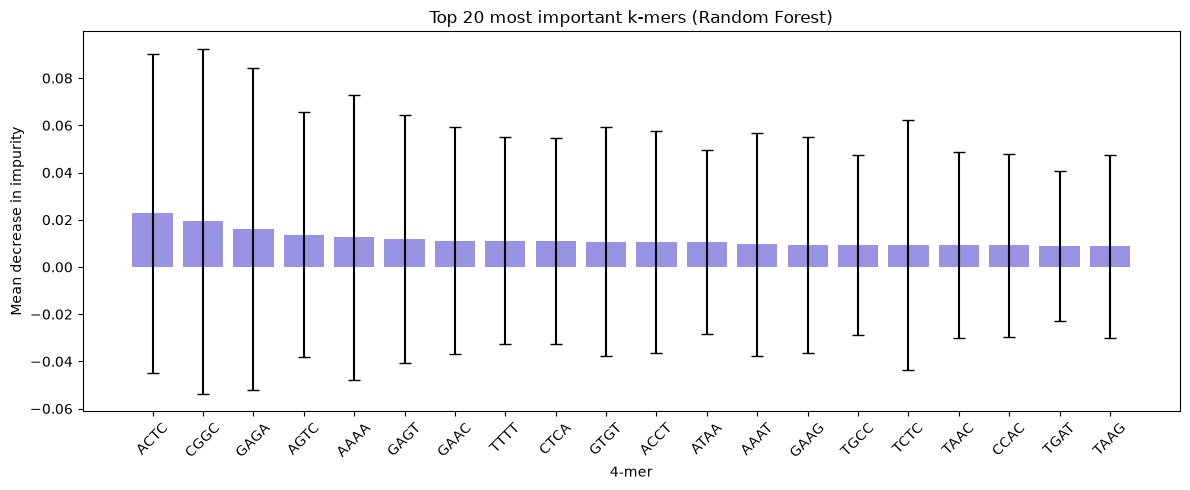


Top 10 predictive k-mers:
  ACTC  importance=0.02273 ± 0.06757
  CGGC  importance=0.01936 ± 0.07315
  GAGA  importance=0.01606 ± 0.06815
  AGTC  importance=0.01370 ± 0.05179
  AAAA  importance=0.01251 ± 0.06047
  GAGT  importance=0.01180 ± 0.05262
  GAAC  importance=0.01118 ± 0.04816
  TTTT  importance=0.01106 ± 0.04382
  CTCA  importance=0.01098 ± 0.04375
  GTGT  importance=0.01070 ± 0.04846


In [11]:
# Reconstruct vocabulary
vocab = [''.join(p) for p in product('ACGT', repeat=4)]

# Gett importance scores from the trained model
importances = model.feature_importances_
std_devs = np.std([tree.feature_importances_ for tree in model.estimators_], axis=0)

# Sort by importance
sorted_idx = np.argsort(importances)[::-1]
top_n = 20

top_kmers  = [vocab[i] for i in sorted_idx[:top_n]]
top_scores = importances[sorted_idx[:top_n]]
top_std    = std_devs[sorted_idx[:top_n]]

# Plot
fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(top_kmers, top_scores, yerr=top_std,
              color="#7F77DD", alpha=0.8, capsize=4)
ax.set_title(f"Top {top_n} most important k-mers (Random Forest)")
ax.set_xlabel("4-mer")
ax.set_ylabel("Mean decrease in impurity")
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig('../plots/most_important_kmers.png', dpi=500, bbox_inches='tight')
plt.show()

print(f"\nTop 10 predictive k-mers:")
for i in range(10):
    print(f"  {top_kmers[i]}  importance={top_scores[i]:.5f} ± {top_std[i]:.5f}")

In [12]:
# Save model
model_path = "../models/random_forest_amr.joblib"
joblib.dump(best_model, model_path)

# Save metadata alongside it
metadata = {
    "trained_on":     datetime.now().isoformat(),
    "n_train":        int(X_train.shape[0]),
    "n_test":         int(X_test.shape[0]),
    "n_features":     int(X.shape[1]),
    "kmer_k":         4,
    "class_weight":   "balanced",
    "class_dist_train": np.bincount(y_train).tolist(),
    "cv_recall_mean": float(cv_results['test_recall'].mean()),
    "cv_recall_std":  float(cv_results['test_recall'].std()),
}

with open("../models/model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)